In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
import os
import torch
import numpy as np
import matplotlib.pyplot as plt

DATA_DIR = "/kaggle/input/datasets/sangatichapla/bradd-s1/BraDD-S1TS_zenodo"

# Find a .pt file
pt_file = None

for root, dirs, files in os.walk(DATA_DIR):
    for file in files:
        if file.endswith(".pt"):
            pt_file = os.path.join(root, file)
            break
    if pt_file:
        break

print("Selected file:", pt_file)

sample = torch.load(pt_file, map_location="cpu")

print("Type:", type(sample))

if isinstance(sample, dict):
    print("Keys:", sample.keys())

    for key, value in sample.items():
        if torch.is_tensor(value):
            print(key, value.shape, value.dtype)

Selected file: /kaggle/input/datasets/sangatichapla/bradd-s1/BraDD-S1TS_zenodo/close_stats.pt
Type: <class 'dict'>
Keys: dict_keys(['mean', 'std', 'min', 'max'])
mean torch.Size([2]) torch.float32
std torch.Size([2]) torch.float32
min torch.Size([]) torch.float32
max torch.Size([]) torch.float32


In [2]:
import os

DATA_DIR = "/kaggle/input/datasets/sangatichapla/bradd-s1/BraDD-S1TS_zenodo"

pt_files = []

for root, dirs, files in os.walk(DATA_DIR):
    for file in files:
        if file.endswith(".pt"):
            pt_files.append(os.path.join(root, file))

print("Total .pt files:", len(pt_files))

for f in pt_files[:30]:
    print(f)

Total .pt files: 25989
/kaggle/input/datasets/sangatichapla/bradd-s1/BraDD-S1TS_zenodo/close_stats.pt
/kaggle/input/datasets/sangatichapla/bradd-s1/BraDD-S1TS_zenodo/Samples/0008331_2021-07-27.pt
/kaggle/input/datasets/sangatichapla/bradd-s1/BraDD-S1TS_zenodo/Samples/0006130_2021-07-27.pt
/kaggle/input/datasets/sangatichapla/bradd-s1/BraDD-S1TS_zenodo/Samples/0011640_2020-08-06.pt
/kaggle/input/datasets/sangatichapla/bradd-s1/BraDD-S1TS_zenodo/Samples/0026120_None.pt
/kaggle/input/datasets/sangatichapla/bradd-s1/BraDD-S1TS_zenodo/Samples/0007546_2020-08-20.pt
/kaggle/input/datasets/sangatichapla/bradd-s1/BraDD-S1TS_zenodo/Samples/0032577_None.pt
/kaggle/input/datasets/sangatichapla/bradd-s1/BraDD-S1TS_zenodo/Samples/0035873_None.pt
/kaggle/input/datasets/sangatichapla/bradd-s1/BraDD-S1TS_zenodo/Samples/0026806_None.pt
/kaggle/input/datasets/sangatichapla/bradd-s1/BraDD-S1TS_zenodo/Samples/0013034_2021-08-19.pt
/kaggle/input/datasets/sangatichapla/bradd-s1/BraDD-S1TS_zenodo/Samples/0023

In [13]:
import torch
import numpy as np
import matplotlib.pyplot as plt

FILE = "/kaggle/input/datasets/sangatichapla/bradd-s1/BraDD-S1TS_zenodo/Samples/0008331_2021-07-27.pt"

sample = torch.load(
    FILE,
    map_location="cpu",
    weights_only=False
)

image = sample["image"]
label = sample["label"]

print("Image shape:", image.shape)
print("Label shape:", label.shape)

Image shape: torch.Size([31, 2, 48, 48])
Label shape: torch.Size([2, 48, 48])


In [14]:
t = 0

sar_ch1 = image[t, 0].numpy()
sar_ch2 = image[t, 1].numpy()

print("Date:", sample["image_dates"][t])

print("\nChannel 1")
print("Min:", sar_ch1.min())
print("Max:", sar_ch1.max())
print("Mean:", sar_ch1.mean())
print("Std:", sar_ch1.std())

print("\nChannel 2")
print("Min:", sar_ch2.min())
print("Max:", sar_ch2.max())
print("Mean:", sar_ch2.mean())
print("Std:", sar_ch2.std())

Date: 2020-08-06

Channel 1
Min: -21.494139
Max: -1.2544575
Mean: -9.33992
Std: 2.878812

Channel 2
Min: -34.921062
Max: -8.506416
Mean: -15.625024
Std: 2.9948874


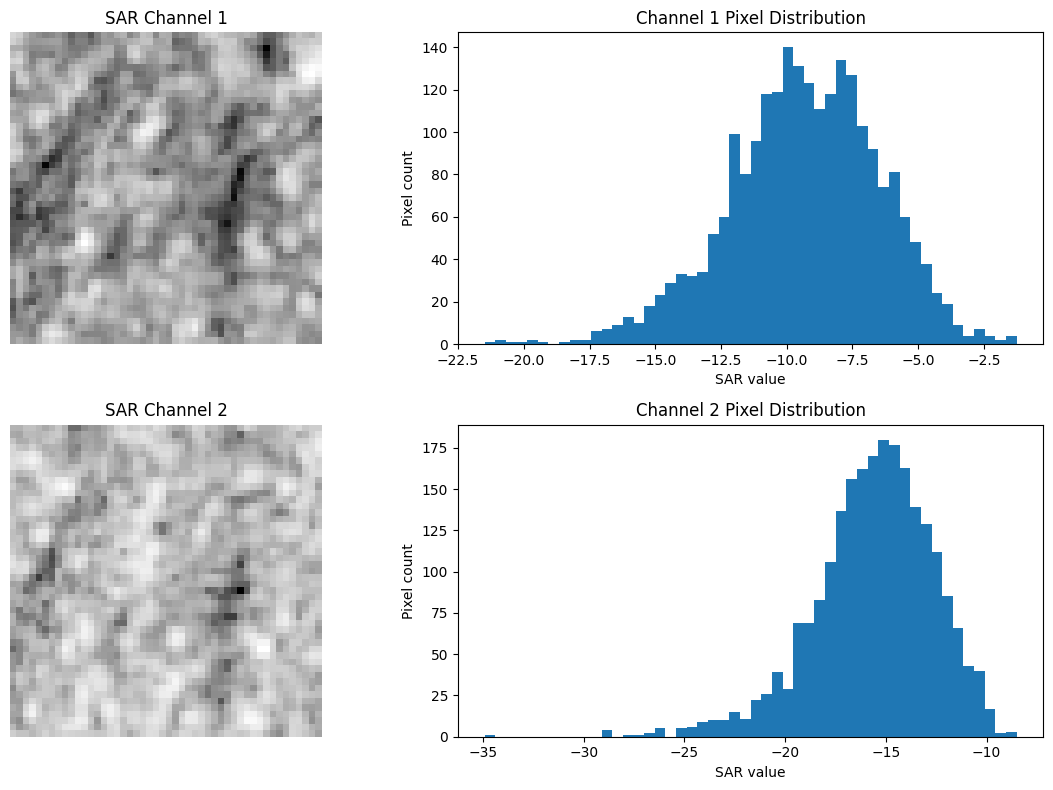

In [15]:
# Visualize raster values + their distributions

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0, 0].imshow(sar_ch1, cmap="gray")
axes[0, 0].set_title("SAR Channel 1")
axes[0, 0].axis("off")

axes[0, 1].hist(sar_ch1.flatten(), bins=50)
axes[0, 1].set_title("Channel 1 Pixel Distribution")
axes[0, 1].set_xlabel("SAR value")
axes[0, 1].set_ylabel("Pixel count")

axes[1, 0].imshow(sar_ch2, cmap="gray")
axes[1, 0].set_title("SAR Channel 2")
axes[1, 0].axis("off")

axes[1, 1].hist(sar_ch2.flatten(), bins=50)
axes[1, 1].set_title("Channel 2 Pixel Distribution")
axes[1, 1].set_xlabel("SAR value")
axes[1, 1].set_ylabel("Pixel count")

plt.tight_layout()
plt.show()